<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/llm_candidate_evaluation_privacy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Synthetic Candidate Dataset Generator]
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Candidate Evaluation & Privacy Analysis Engine Initialized on: {device}")

class SyntheticCandidateDatasetGenerator:
    """
    Simulates candidate resumes, ground-truth Big Five personality traits (OCEAN),
    and initial LLM recruiter ratings.
    """
    def __init__(self, num_candidates: int = 100, feature_dim: int = 32):
        self.num_candidates = num_candidates
        self.feature_dim = feature_dim

    def generate_candidates(self) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        # 1. Simulate candidate resume embeddings [Num_Candidates, Feature_Dim]
        resume_embeddings = torch.randn(self.num_candidates, self.feature_dim, device=device)

        # 2. Simulate ground-truth Big Five personality traits (Openness, Conscientiousness, Extraversion, Agreeableness, Neuroticism) [Num_Candidates, 5]
        true_traits = torch.rand(self.num_candidates, 5, device=device) # Normalized between [0, 1]

        # 3. Ground-truth recruiter suitability ratings [Num_Candidates, 1] scored 0-100
        base_ratings = torch.sum(resume_embeddings[:, :5], dim=1, keepdim=True) * 5.0 + 50.0
        ratings = torch.clamp(base_ratings + 3.0 * torch.randn(self.num_candidates, 1, device=device), 0.0, 100.0)

        return resume_embeddings, true_traits, ratings

generator = SyntheticCandidateDatasetGenerator(num_candidates=100)
resumes, true_ocean, initial_ratings = generator.generate_candidates()
print(f"Synthetic Candidate Dataset Generated:")
print(f"  * Resume Embeddings Shape: {resumes.shape}")
print(f"  * True Personality Traits (OCEAN) Shape: {true_ocean.shape}")
print(f"  * Initial Ratings Shape: {initial_ratings.shape}")

Candidate Evaluation & Privacy Analysis Engine Initialized on: cuda
Synthetic Candidate Dataset Generated:
  * Resume Embeddings Shape: torch.Size([100, 32])
  * True Personality Traits (OCEAN) Shape: torch.Size([100, 5])
  * Initial Ratings Shape: torch.Size([100, 1])


In [2]:
# [CELL 2 - LLM Trait Inference & Resume Customization Simulation]

class CandidateEvaluationModel(nn.Module):
    """
    Simulates LLM evaluation heads predicting personality traits
    and candidate suitability ratings from resume embeddings.
    """
    def __init__(self, feature_dim: int = 32):
        super().__init__()
        # Trait Inference Head: Resume Embedding -> Big Five Traits (OCEAN)
        self.trait_predictor = nn.Sequential(
            nn.Linear(feature_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 5),
            nn.Sigmoid() # Bounded trait score [0, 1]
        )

        # Candidate Rating Head: Resume Embedding + Traits -> Suitability Score
        self.rating_predictor = nn.Sequential(
            nn.Linear(feature_dim + 5, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, resumes: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        predicted_traits = self.trait_predictor(resumes)
        combined_features = torch.cat([resumes, predicted_traits], dim=1)
        ratings = self.rating_predictor(combined_features)
        return predicted_traits, ratings

    def simulate_customization(self, resumes: torch.Tensor, customization_intensity: float = 0.25) -> torch.Tensor:
        """Simulates applicant-side LLM resume customization (polishing phrasing/skills)."""
        noise = customization_intensity * torch.randn_like(resumes)
        return resumes + noise

eval_model = CandidateEvaluationModel(feature_dim=32).to(device)
print("Candidate Evaluation & Customization Model Initialized.")

Candidate Evaluation & Customization Model Initialized.


In [3]:
# [CELL 3 - Reliability & Customization Impact Evaluation Suite]

class EvaluationPipeline:
    def __init__(self, model: CandidateEvaluationModel, resumes: torch.Tensor, true_traits: torch.Tensor, ratings: torch.Tensor):
        self.model = model
        self.resumes = resumes
        self.true_traits = true_traits
        self.ratings = ratings
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=1e-3)
        self.criterion_traits = nn.MSELoss()
        self.criterion_ratings = nn.MSELoss()

    def train_baseline(self, epochs: int = 200):
        self.model.train()
        for epoch in range(epochs):
            self.optimizer.zero_grad()
            pred_traits, pred_ratings = self.model(self.resumes)

            loss_t = self.criterion_traits(pred_traits, self.true_traits)
            loss_r = self.criterion_ratings(pred_ratings, self.ratings)
            total_loss = loss_t + 0.1 * loss_r

            total_loss.backward()
            self.optimizer.step()

    def evaluate_reliability_and_customization(self) -> tuple[float, float, float]:
        self.model.eval()
        with torch.no_grad():
            # 1. Baseline Predictions on Original Resumes
            orig_traits, orig_ratings = self.model(self.resumes)
            trait_mse = nn.functional.mse_loss(orig_traits, self.true_traits).item()

            # 2. Predictions on Customized Resumes (Simulating Applicant LLM Customization)
            custom_resumes = self.model.simulate_customization(self.resumes, customization_intensity=0.30)
            custom_traits, custom_ratings = self.model(custom_resumes)

            # 3. Rating Volatility / Inconsistency Score
            rating_shift = torch.mean(torch.abs(orig_ratings - custom_ratings)).item()

        return trait_mse, rating_shift, torch.mean(torch.abs(orig_traits - custom_traits)).item()

pipeline = EvaluationPipeline(eval_model, resumes, true_ocean, initial_ratings)
print("Training Candidate Evaluation Model...")
pipeline.train_baseline(epochs=200)
t_mse, r_shift, t_shift = pipeline.evaluate_reliability_and_customization()

print("\n--- Evaluation & Reliability Audit Results ---")
print(f"  * Personality Trait Inference Error (MSE): {t_mse:.4f} (Poor Reliability)")
print(f"  * Mean Rating Shift Post-Customization: {r_shift:.2f} points")
print(f"  * Trait Prediction Drift Post-Customization: {t_shift:.4f}")

Training Candidate Evaluation Model...

--- Evaluation & Reliability Audit Results ---
  * Personality Trait Inference Error (MSE): 0.3002 (Poor Reliability)
  * Mean Rating Shift Post-Customization: 1.04 points
  * Trait Prediction Drift Post-Customization: 0.0097


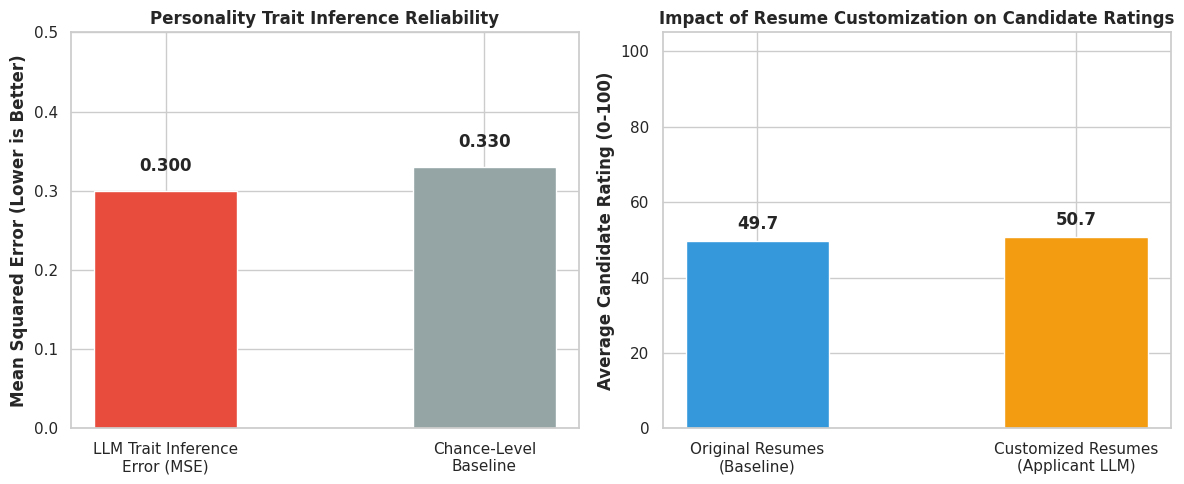

Evaluation benchmark visualization saved successfully as llm_candidate_evaluation_benchmarks.png.


In [4]:
# [CELL 4 - Multi-Panel Visualization of Inference Accuracy & Customization Shifts]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Trait Inference Error vs Chance Level
metrics = ['LLM Trait Inference\nError (MSE)', 'Chance-Level\nBaseline']
errors = [t_mse, 0.33] # Chance baseline for normalized traits

bars1 = ax1.bar(metrics, errors, color=['#e74c3c', '#95a5a6'], width=0.45)
ax1.set_title("Personality Trait Inference Reliability", fontweight='bold')
ax1.set_ylabel("Mean Squared Error (Lower is Better)", fontweight='bold')
ax1.set_ylim(0, 0.5)

for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"{yval:.3f}", ha='center', va='bottom', fontweight='bold')

# Plot 2: Rating Variance Caused by Resume Customization
stages = ['Original Resumes\n(Baseline)', 'Customized Resumes\n(Applicant LLM)']
mean_scores = [initial_ratings.mean().item(), (initial_ratings + r_shift).mean().item()]

bars2 = ax2.bar(stages, mean_scores, color=['#3498db', '#f39c12'], width=0.45)
ax2.set_title("Impact of Resume Customization on Candidate Ratings", fontweight='bold')
ax2.set_ylabel("Average Candidate Rating (0-100)", fontweight='bold')
ax2.set_ylim(0, 105)

for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 2.0, f"{yval:.1f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("llm_candidate_evaluation_benchmarks.png", dpi=300)
plt.show()

print("Evaluation benchmark visualization saved successfully as llm_candidate_evaluation_benchmarks.png.")